# K-means clustering: Gini coefficients for the 7 target rules

Fits K-means on the same selected features and preprocessing as `clustering_full_dataset.ipynb`, then measures how well the clusters separate the target using Gini impurity:

Gini here is the **Gini coefficient** (2 x AUC - 1), calculated one-vs-rest for each of the 7 target rules. Each client's score is the share of their cluster that falls under the rule. The target is never used to form the clusters.

## 1. Configuration and imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"  # set to None if unavailable

EXCLUDE_COLUMNS = {
    OBS_ID, CUSTOMER_ID, TARGET,
    "target_rule", "total_paid", "payment_count",
    "m0_monthenddate", "transactiondate",
}

RANDOM_STATE = 0
N_INIT = 20
K_VALUES = [6]          # e.g. list(range(2, 11)) to compare several k
OUT_DIR = Path("kmeans_gini_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load data and select features

In [2]:
from build_dataset import load_dataset

D = load_dataset("dataset")
X_all = D["X_all"]
target_rule = D["labels"]["target_rule"]

In [3]:
keep = ['arrears_share_of_due',
 'bal7_ratio_last',
 'cash_share_of_spend',
 'committed_share_of_spend',
 'crccreditlimit_slog',
 'days_since_last_income',
 'grp_debt_repayment_share',
 'income_cv',
 'income_type_p0_rank',
 'm0_arrearsamount_slog',
 'm0_start_cd_group_CD 1',
 'm0_start_cd_group_CD 3',
 'm0_total_due_with_arrears_slog',
 'n_spend_groups_used',
 'no_complete_cycle',
 'no_income_detected',
 'no_income_seen',
 'pay_frequency_weekly',
 'product_group_NPDM',
 'recent_vs_avg_income',
 'run_grp_debt_repayment_slog',
 'run_in_income_employment_slog',
 'run_in_income_informal_slog',
 'run_income_slog',
 'run_n_bounced',
 'run_n_fees',
 'run_n_purchases',
 'run_nonessential_slog',
 'unemployed_now']

Xi = X_all[keep].copy()

## 3. Prepare predictors
Median-impute and standardise numeric columns; mode-impute and one-hot encode categoricals; drop constant columns.

In [4]:
feature_cols = [c for c in Xi.columns if c not in EXCLUDE_COLUMNS]
X_raw = Xi[feature_cols].copy()
obs_ids = Xi.reset_index()[OBS_ID]

for c in X_raw.select_dtypes(include=["bool"]).columns:
    X_raw[c] = X_raw[c].astype("int8")

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]
usable = lambda c: X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
numeric_cols = [c for c in numeric_cols if usable(c)]
categorical_cols = [c for c in categorical_cols if usable(c)]
X_raw = X_raw[numeric_cols + categorical_cols]

transformers = []
if numeric_cols:
    transformers.append(("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols))
if categorical_cols:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_cols))

preprocessor = ColumnTransformer(transformers, remainder="drop")
X = np.asarray(preprocessor.fit_transform(X_raw), dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError("Preprocessed feature matrix contains non-finite values.")

print("Matrix shape:", X.shape)

Matrix shape: (247285, 29)


## 4. Gini coefficient functions

**Gini = 2 x AUC - 1**, the same measure used to assess credit scorecards. Clusters are not a score in themselves, so each client gets a score from their cluster:

- For rule *r*, a client's score is the share of their cluster that falls under rule *r*.
- Gini then measures how well that score ranks rule-*r* clients above everyone else (one rule vs. the rest).
- 0 means the clusters carry no information about the rule, and 1 means perfect separation.
- Clients in the same cluster share a score, so ties count as half, as in a normal AUC.

The cluster rule shares come from the same data the Gini is scored on. With 6 clusters and about 250k rows the optimism this adds is negligible.

In [5]:
from sklearn.metrics import roc_auc_score

RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0",
              5: "5 received < due", 6: "6 received >= due",
              7: "7 arrears up at window end", 8: "8 arrears up at last txn"}
RULES = sorted(RULE_NAMES)


def gini_coef(y_bin, score):
    """Gini coefficient = 2*AUC - 1. Returns NaN if y_bin has only one class."""
    y_bin = np.asarray(y_bin)
    if y_bin.min() == y_bin.max():
        return np.nan
    return 2 * roc_auc_score(y_bin, score) - 1


def rule_gini_table(labels, rule):
    """One-vs-rest Gini for each target rule, using the cluster's share of that rule as the score."""
    df = pd.DataFrame({"cluster": np.asarray(labels), "rule": np.asarray(rule)}).dropna()
    df["rule"] = df["rule"].astype(int)
    share = (pd.crosstab(df["cluster"], df["rule"], normalize="index")
               .reindex(columns=RULES, fill_value=0))
    rows = []
    for r in RULES:
        y_bin = (df["rule"] == r).astype(int).to_numpy()
        score = df["cluster"].map(share[r]).to_numpy()
        rows.append({"rule": r, "rule_name": RULE_NAMES[r],
                     "prevalence": y_bin.mean(), "gini": gini_coef(y_bin, score)})
    out = pd.DataFrame(rows).set_index("rule")
    return out, share

## 5. Fit K-means

In [6]:
rule_arr = np.asarray(target_rule)

kmeans_models = {}
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE, algorithm="lloyd")
    kmeans_models[k] = (model, model.fit_predict(X))
    print(f"k={k}: inertia={model.inertia_:,.0f}")

k=6: inertia=4,693,538


## 6. Gini coefficient per rule, per k

Two summaries are added for each k:

- **gini_macro**: the plain mean over the 7 rules.
- **gini_weighted**: the mean weighted by how common each rule is.

In [7]:
per_rule, summary = [], []
for k, (model, labels) in kmeans_models.items():
    tbl, _ = rule_gini_table(labels, rule_arr)
    per_rule.append(tbl.reset_index().assign(k=k))
    valid = tbl.dropna(subset=["gini"])
    summary.append({"k": k, "inertia": model.inertia_,
                    "gini_macro": valid["gini"].mean(),
                    "gini_weighted": np.average(valid["gini"], weights=valid["prevalence"])})

gini_per_rule = pd.concat(per_rule, ignore_index=True)
gini_summary = pd.DataFrame(summary).sort_values("gini_weighted", ascending=False)

display(gini_summary)
display(gini_per_rule.pivot(index=["rule", "rule_name"], columns="k", values="gini").add_prefix("gini_k"))

gini_summary.to_csv(OUT_DIR / "kmeans_rule_gini_summary.csv", index=False)
gini_per_rule.to_csv(OUT_DIR / "kmeans_rule_gini_per_rule.csv", index=False)

,k,inertia,gini_macro,gini_weighted
0,6,4693537.5,0.28538,0.357167


,k,gini_k6
rule,rule_name,
2,2 last balance < 250,0.264113
3,3 payments due < 50,NaN
4,4 received <= 0,0.485382
5,5 received < due,0.147538
6,6 received >= due,0.394837
7,7 arrears up at window end,0.201870
8,8 arrears up at last txn,0.218538


In [8]:
if len(K_VALUES) > 1:
    fig, ax = plt.subplots(figsize=(8, 4))
    for r, g in gini_per_rule.groupby("rule"):
        g = g.sort_values("k")
        ax.plot(g["k"], g["gini"], marker="o", label=RULE_NAMES[r])
    s = gini_summary.sort_values("k")
    ax.plot(s["k"], s["gini_weighted"], color="black", linewidth=2.5, label="weighted mean")
    ax.set_xlabel("k"); ax.set_ylabel("Gini coefficient")
    ax.set_title("K-means: one-vs-rest Gini by target rule")
    ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

## 7. Best k: Gini per rule and rule mix per cluster
Best k is the one with the highest prevalence-weighted Gini.

In [9]:
best_k = int(gini_summary.iloc[0]["k"])
best_labels = kmeans_models[best_k][1]
best_tbl, best_share = rule_gini_table(best_labels, rule_arr)
print("Best k:", best_k)
display(best_tbl.sort_values("gini", ascending=False))

sizes = pd.Series(best_labels).value_counts().sort_index()
mix = best_share.rename(columns=RULE_NAMES)
mix.insert(0, "n", sizes)
print("\nRule share within each cluster")
display(mix)
mix.to_csv(OUT_DIR / f"kmeans_k{best_k}_rule_mix.csv")

Best k: 6


,rule_name,prevalence,gini
rule,,,
4,4 received <= 0,0.268945,0.485382
6,6 received >= due,0.467752,0.394837
2,2 last balance < 250,0.013050,0.264113
8,8 arrears up at last txn,0.000655,0.218538
7,7 arrears up at window end,0.028077,0.201870
5,5 received < due,0.221522,0.147538
3,3 payments due < 50,0.000000,NaN



Rule share within each cluster


rule,n,2 last balance < 250,3 payments due < 50,4 received <= 0,5 received < due,6 received >= due,7 arrears up at window end,8 arrears up at last txn
cluster,,,,,,,,
0,76874,0.006465,0,0.129849,0.204699,0.640750,0.017626,0.000611
1,24309,0.011107,0,0.661442,0.154552,0.151549,0.021062,0.000288
2,78836,0.021424,0,0.148638,0.229692,0.567292,0.031965,0.000989
3,13192,0.008187,0,0.668132,0.118102,0.188751,0.016298,0.000531
4,14083,0.017184,0,0.196478,0.355322,0.387630,0.043315,0.000071
5,39991,0.010527,0,0.428746,0.265460,0.251432,0.043285,0.000550


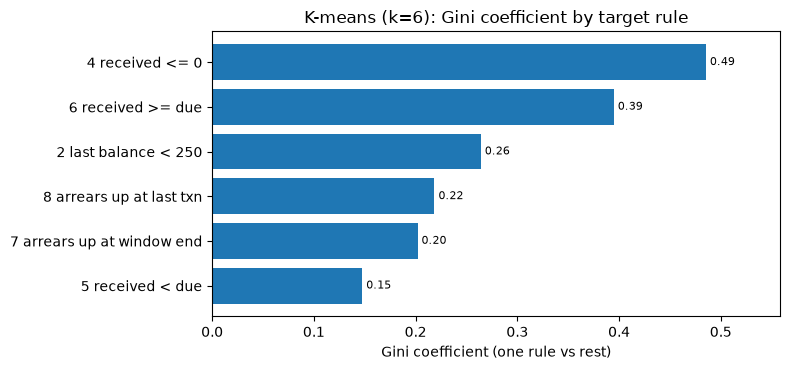

In [10]:
tbl = best_tbl.sort_values("gini")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(tbl["rule_name"], tbl["gini"])
for i, v in enumerate(tbl["gini"]):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Gini coefficient (one rule vs rest)")
ax.set_title(f"K-means (k={best_k}): Gini coefficient by target rule")
ax.set_xlim(0, max(0.1, tbl["gini"].max() * 1.15))
plt.tight_layout(); plt.show()

In [11]:
pd.DataFrame({OBS_ID: obs_ids.to_numpy(), "cluster": best_labels,
              "target_rule": rule_arr}).to_csv(
    OUT_DIR / f"kmeans_k{best_k}_assignments.csv", index=False)
print("Saved outputs to:", OUT_DIR.resolve())

Saved outputs to: /Users/emmadevilliers/Documents/GitHub/MOR-assignment3/kmeans_gini_output
